In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from src.config import *
RES = RES_DIR
def show(name, width=900):
    display(Image(filename=str(FIG_DIR / f"{name}.png"), width=width))


# 05 · Concept drift analysis

**Questions.** Where does performance collapse (RQ2)? Can retraining or removing unstable features reduce the damage (RQ4)? Which features matter and does that change? What do the errors look like?

> Step 43 is commonly linked to the shutdown of a major darknet market. This is a **plausible hypothesis, not something this dataset can prove**: we observe *when* behaviour changes, not *why*.

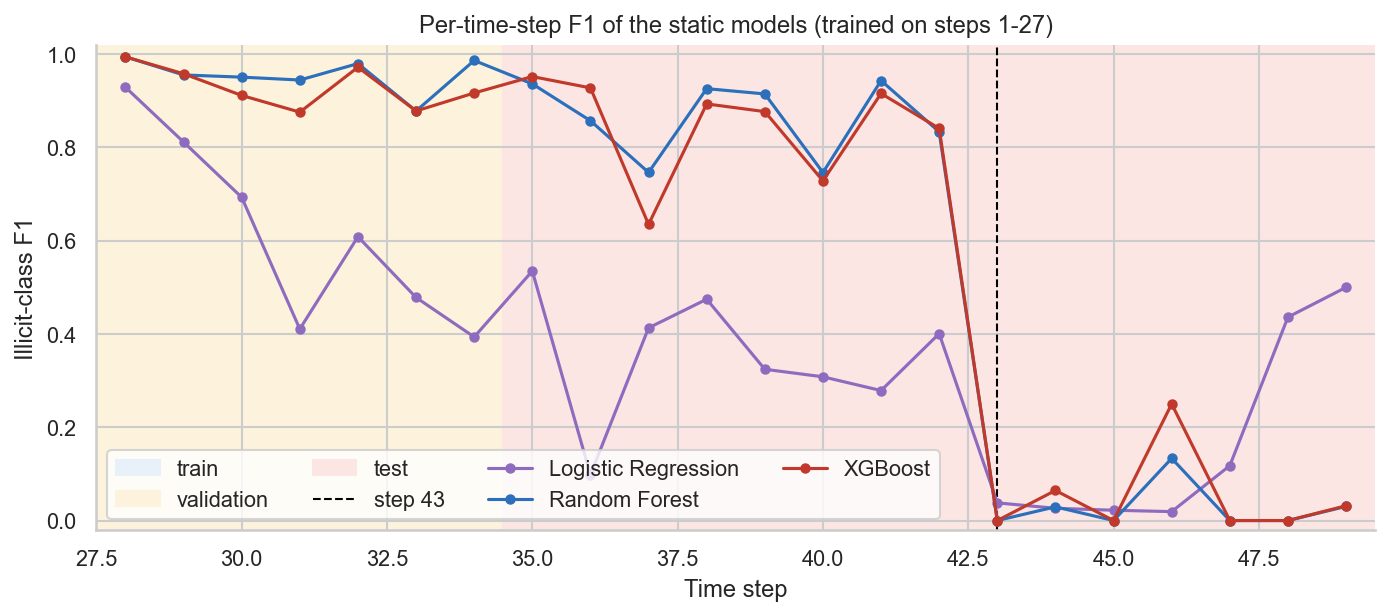

In [2]:
from src import plots
ps = pd.read_csv(RES / "per_step_metrics.csv")
pst = ps[ps.period.isin(["val", "test"])]
plots.fig_per_step(pst, ["logreg", "rf", "xgb"], "f1", "drift_01_per_step_f1"); show("drift_01_per_step_f1", 1000)

**Insight (RQ2).** All models are strong from step 28 to 42 and then collapse at **step 43**. Random Forest and XGBoost score per-step F1 between 0.63 and 0.95 for steps 35-42, and then 0.00 at step 43, near zero (0.00-0.06) in steps 44-49 apart from a single noisy spike at step 46, which has only 2 illicit transactions. Logistic Regression is poor throughout.

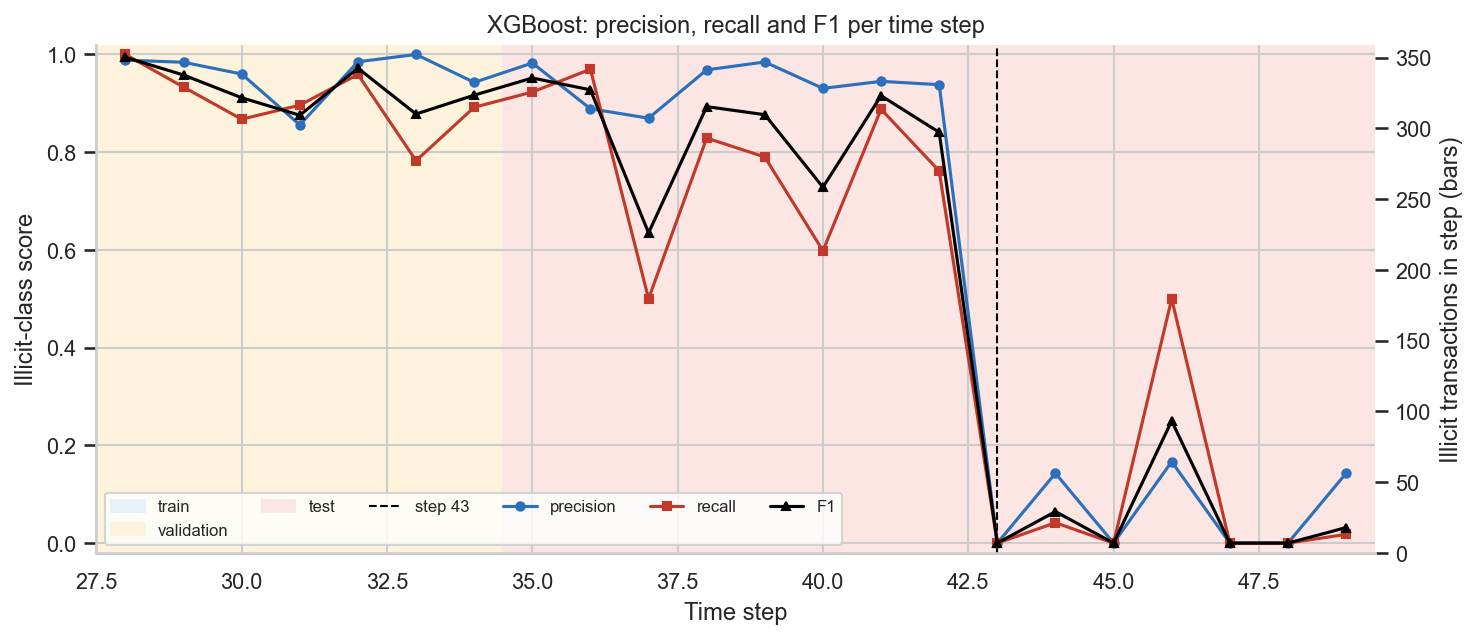

time_step,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49
precision,0.98,0.89,0.87,0.97,0.98,0.93,0.94,0.94,0.0,0.14,0.0,0.17,0.0,0.0,0.14
recall,0.92,0.97,0.50,0.83,0.79,0.60,0.89,0.76,0.0,0.04,0.0,0.50,0.0,0.0,0.02
f1,0.95,0.93,0.63,0.89,0.88,0.73,0.92,0.84,0.0,0.06,0.0,0.25,0.0,0.0,0.03
n_illicit,182.00,33.00,40.00,111.00,81.00,112.00,116.00,239.00,24.0,24.00,5.0,2.00,22.0,36.0,56.00


In [3]:
plots.fig_per_step_prf(pst, "xgb"); show("drift_02_per_step_prf_xgb", 1000)
t = pst[(pst.period == "test") & (pst.model == "xgb")].set_index("time_step")[["precision", "recall", "f1", "n_illicit"]].round(2); t.T

**Insight.** Before step 43 the XGBoost model has precision 0.87-0.98 and recall between 0.50 and 0.97; after it, recall is 0 at steps 43, 45, 47, 48 and about 0.02-0.04 at steps 44 and 49 (step 46 shows 0.50, but on only 2 illicit transactions). It still has alarms (low false-positive counts), but it simply does not recognise the illicit transactions of the new period. The bars show that several late steps contain few illicit transactions, so single-step values must be read with caution; the pooled picture (3 of 169 illicit transactions caught in steps 43-49) is the reliable one.

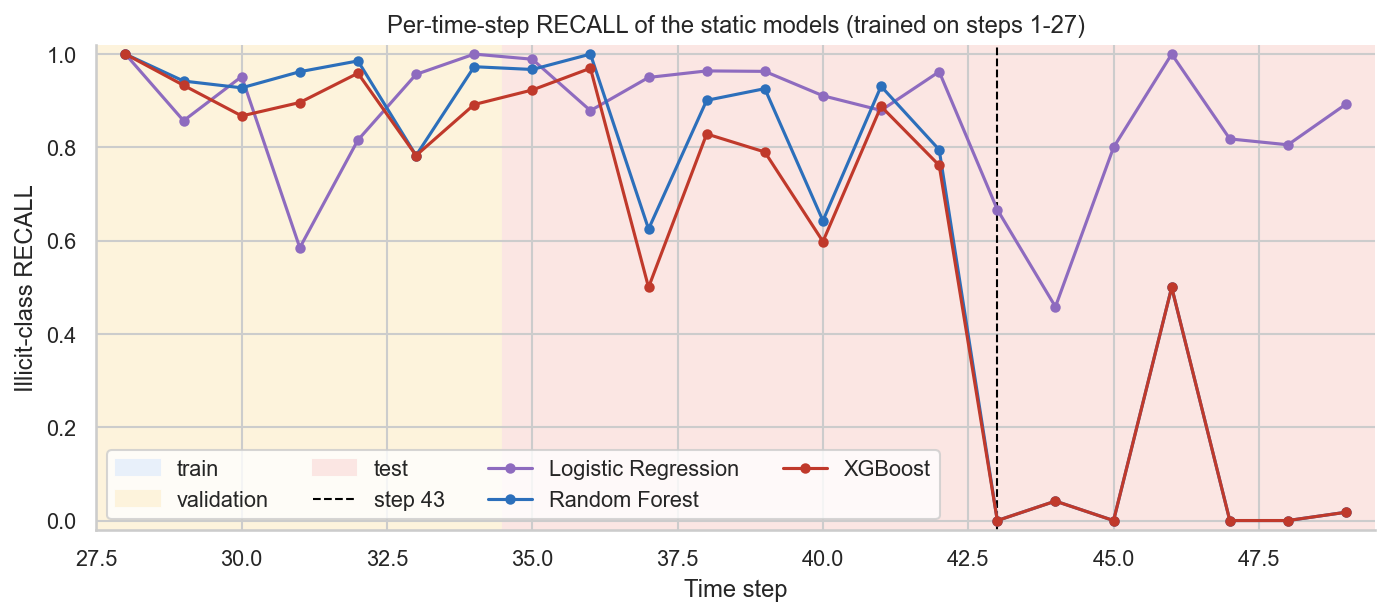

In [4]:
show("drift_01b_per_step_recall", 1000)

**Insight.** Recall tells the same story as F1: the loss is a loss of *detection*, not a flood of false positives.

### Why do the models fail after step 43? Error analysis

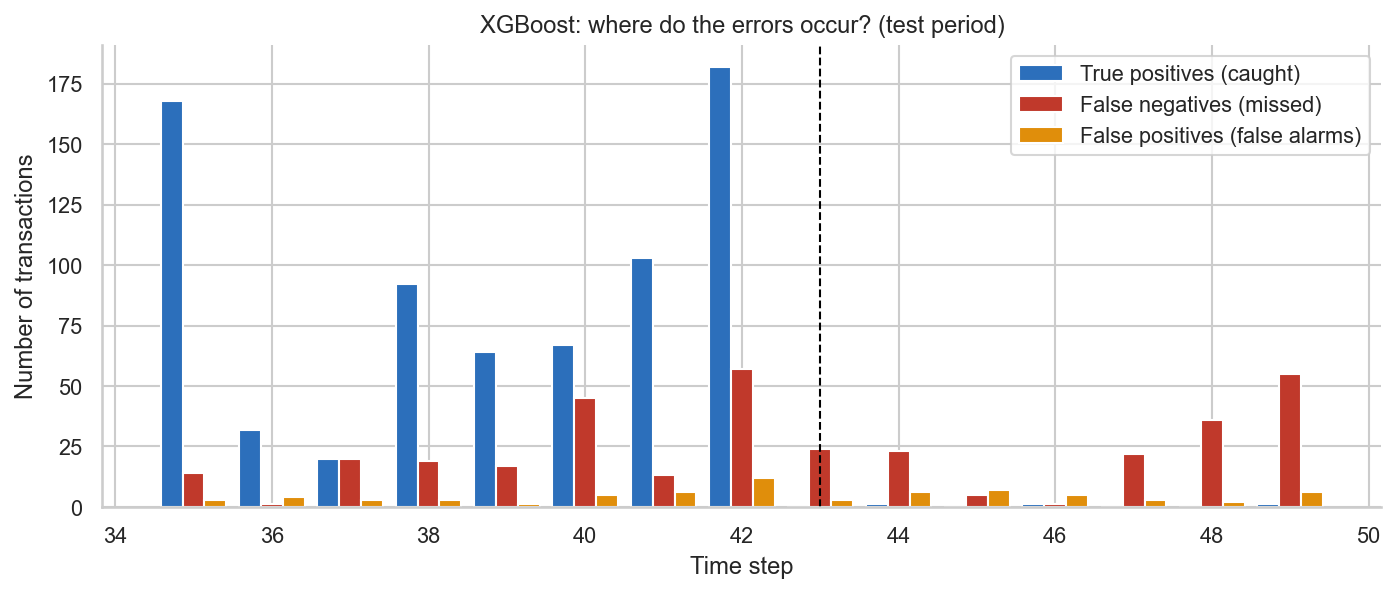

outcome,FN,FP,TN,TP
time_step,,,,
steps 35-42,186,37,9032,728
steps 43-49,166,32,6486,3


mean illicit probability  caught (TP): 0.975 | missed (FN): 0.080 | share of FN with probability < 0.1: 79%


In [5]:
show("err_01_errors_by_step_xgb", 1000)
oc = pd.read_parquet(RES / "xgb_test_outcomes.parquet")
display(oc.groupby([oc.time_step >= 43, "outcome"]).size().unstack(fill_value=0).rename(index={False: "steps 35-42", True: "steps 43-49"}))
fn, tp = oc[oc.outcome == "FN"], oc[oc.outcome == "TP"]
print("mean illicit probability  caught (TP): %.3f | missed (FN): %.3f | share of FN with probability < 0.1: %.0f%%" % (tp.proba.mean(), fn.proba.mean(), 100 * (fn.proba < 0.1).mean()))

**Insight (XGBoost, test period).**
* Of its 352 false negatives, **166 (47%) fall in steps 43-49** even though those steps contain only 169 of the 1,083 illicit test transactions (16%): it catches 3 of 169 there, versus 728 of 914 before step 43.
* **False negatives are confident misses**: 79% of them received an illicit probability below 0.1 (mean 0.08, against 0.975 for caught ones). The model does not sit on the fence; the late-period illicit transactions look licit to it, which is the signature of concept drift rather than of noise.
* False positives are rare and stable (69 in total, about 2-12 per step), so the failure is one of recall.

In [6]:
prof = pd.read_csv(RES / "outcome_feature_profile_z.csv", index_col=0)
prof.loc[["local_53", "local_55", "local_90", "local_41", "local_59"]].round(2)

,TP,FN,FP,TN
feature,,,,
local_53,-1.00,-0.62,-0.88,-0.31
local_55,-0.88,-0.60,-0.79,-0.25
local_90,-0.85,-0.68,-0.72,-0.34
local_41,-0.37,-0.37,-0.37,0.08
local_59,-0.41,-0.41,-0.41,-0.27


**Insight.** On the most discriminative features (shown as z-scores against the training period), caught illicit transactions (TP) are far below average (-1.00 on `local_53`), licit transactions are near the middle (-0.31), and the **missed illicit transactions (FN) lie in between (-0.62)**: they look partly like licit ones, so the learned decision boundary no longer isolates them. We do not interpret what these features measure.

In [7]:
ag = json.loads((RES / "error_agreement_bootstrap.json").read_text()); ag

{'fn_rf': 301,
 'fn_xgb': 352,
 'fn_both': 301,
 'fn_jaccard': 0.8551136363636364,
 'fp_rf': 201,
 'fp_xgb': 69,
 'fp_both': 40,
 'fp_jaccard': 0.17391304347826086,
 'pr_auc_diff_rf_minus_xgb_mean': 0.0007477065028538277,
 'pr_auc_diff_ci': [-0.004560475455100285, 0.005383161720612652],
 'f1_diff_rf_minus_xgb_mean': -0.019746654018139614,
 'f1_diff_ci': [-0.03291027278013817, -0.007165198225869668]}

**Do models fail in the same places?** Largely yes for misses: all 301 illicit transactions missed by Random Forest are also missed by XGBoost (Jaccard overlap 0.86), so the two tree models share the same blind spot, consistent with a data-level cause (drift) rather than a model quirk. For false alarms they differ: only 40 transactions are false positives for both (Jaccard 0.17), so the models disagree about which licit transactions look suspicious.

### Does retraining reduce the damage? (RQ4)
We walk forward through the test period. For each step *t* the model is (re)trained on labelled data from earlier steps only and then scores step *t*:
* **Static**: trained once on steps 1-27;
* **Expanding window**: all labelled steps before *t*;
* **Sliding window**: the last 10 labelled steps before *t*.

*Assumption:* labels for step *t-1* are available when scoring step *t*. This is optimistic (confirming illicit activity takes time). All use the same hyper-parameters and a fixed threshold of 0.5 for a fair comparison.

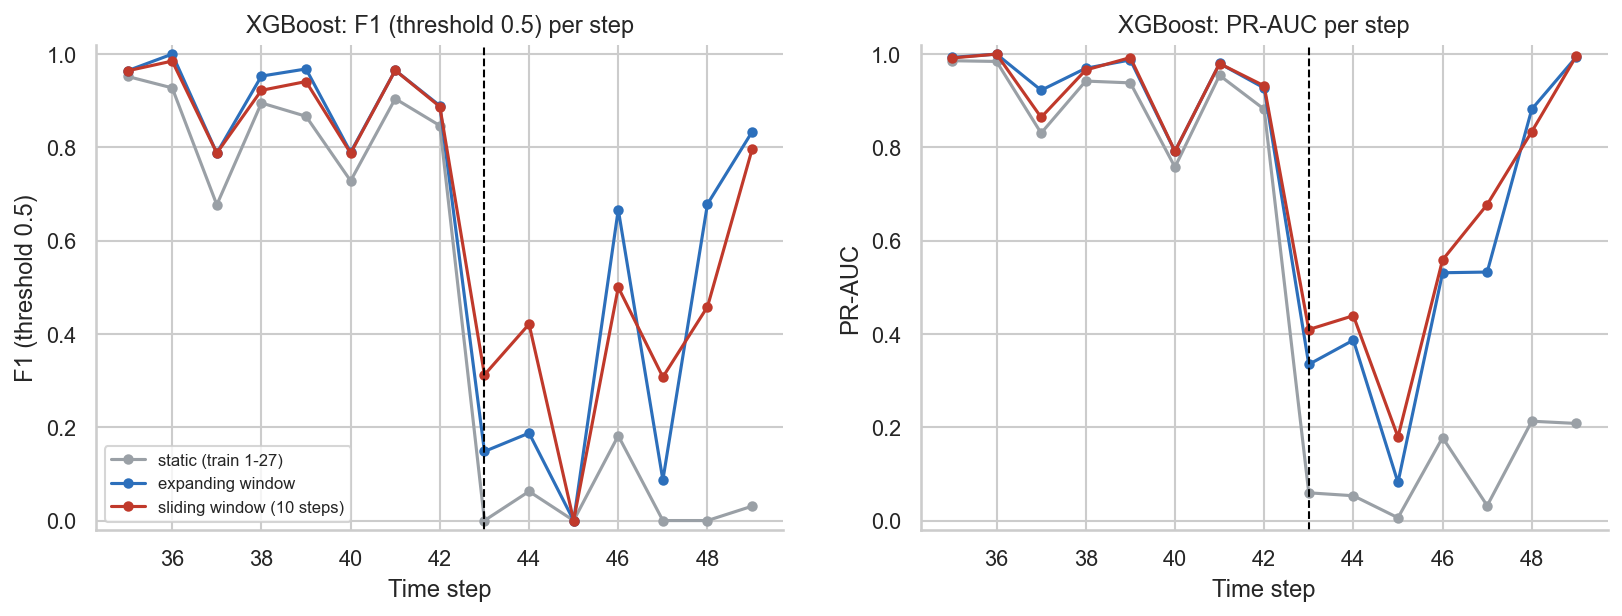

,model,strategy,period,precision,recall,f1,pr_auc
0,rf,static (train 1-27),all_35-49,0.993,0.532,0.693,0.784
1,rf,static (train 1-27),35-42,1.000,0.627,0.771,0.910
2,rf,static (train 1-27),43-49,0.429,0.018,0.034,0.045
3,rf,expanding window,all_35-49,0.995,0.697,0.820,0.898
4,rf,expanding window,35-42,0.999,0.823,0.902,0.933
5,rf,expanding window,43-49,0.500,0.018,0.034,0.565
6,rf,sliding window (10 steps),all_35-49,0.993,0.684,0.810,0.881
7,rf,sliding window (10 steps),35-42,0.997,0.810,0.894,0.926
8,rf,sliding window (10 steps),43-49,0.250,0.006,0.012,0.482
9,xgb,static (train 1-27),all_35-49,0.884,0.684,0.771,0.783


In [8]:
show("drift_03_retraining_xgb", 1100)
rs = pd.read_csv(RES / "retraining_summary.csv")
rs[["model", "strategy", "period", "precision", "recall", "f1", "pr_auc"]].round(3)

**Insight.**
* Pooled over steps 35-49, retraining raises XGBoost F1 from 0.771 (static) to **0.873 (expanding)** and **0.864 (sliding)**, and PR-AUC from 0.783 to 0.915 / 0.913. For Random Forest, F1 rises from 0.693 to 0.820 / 0.810.
* **In the collapsed period (steps 43-49)** XGBoost's recall goes from 0.018 to 0.391 and F1 from 0.027 to 0.543 (expanding) / 0.532 (sliding): retraining recovers *some* ability once labels from the new regime arrive. Random Forest at threshold 0.5 still misses nearly everything there (recall 0.018) although its PR-AUC rises from 0.045 to 0.565, i.e. its ranking improves but its probabilities stay too low for the fixed threshold.
* Sliding and expanding windows perform alike (differences of about 0.01 F1); the sliding window is cheaper and forgets old behaviour but has less data. Expanding is slightly better on average here; neither fully restores pre-collapse performance (F1 0.54 vs about 0.9 earlier).
* **Trade-offs:** needs a steady supply of fresh labels (an operational cost), repeated retraining, and monitoring. Drift is **reduced, not solved.**

### Does removing unstable features help? (RQ4)
Features were ranked by their Kolmogorov-Smirnov shift between the training (1-27) and validation (28-34) periods (no test data used), and the most-shifted fraction was dropped before fitting.

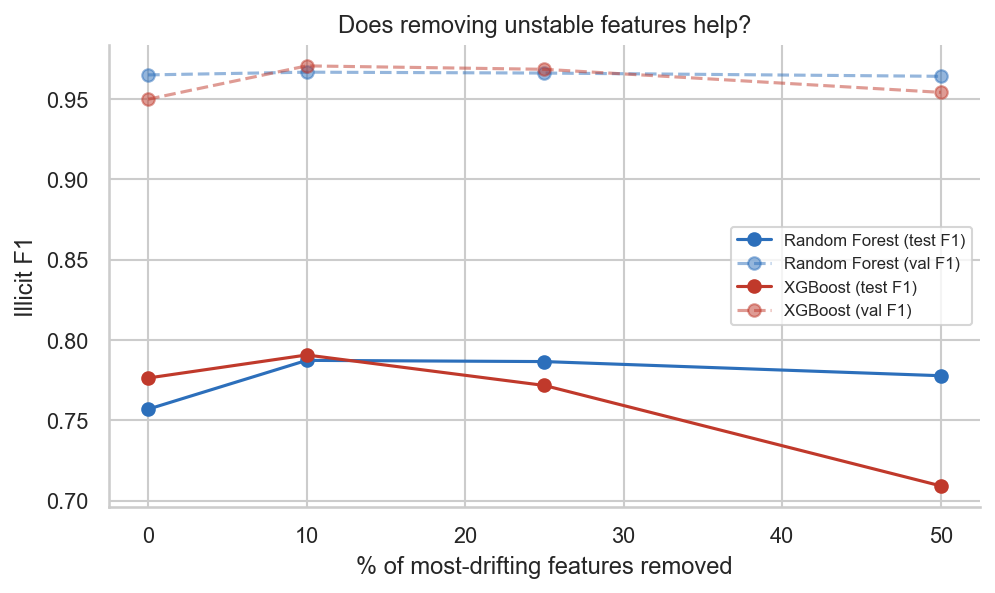

f1        pr_auc       
period                   test    val   test    val
model dropped_fraction                            
rf    0.00              0.757  0.965  0.784  0.989
      0.10              0.787  0.967  0.785  0.990
      0.25              0.787  0.966  0.786  0.989
      0.50              0.778  0.964  0.776  0.986
xgb   0.00              0.776  0.950  0.783  0.985
      0.10              0.791  0.971  0.794  0.991
      0.25              0.772  0.968  0.796  0.992
      0.50              0.709  0.954  0.797  0.986

In [9]:
show("drift_04_unstable_features", 700)
u = pd.read_csv(RES / "unstable_feature_removal.csv")
u.pivot_table(index=["model", "dropped_fraction"], columns="period", values=["f1", "pr_auc"]).round(3)

**Insight.** Dropping the 10% most-shifted features improved validation F1 for both models (RF 0.965 → 0.967, XGBoost 0.950 → 0.971) and test F1 (RF 0.757 → 0.787, XGBoost 0.776 → 0.791); dropping 50% hurt XGBoost (test F1 0.709). Since validation also prefers the 10% setting, this is a legitimate modest gain of about 0.015-0.03 F1, but it is small compared with the collapse after step 43 and is **not a fix for the drift**: those steps are untouched by this change.

### Feature importance and its stability

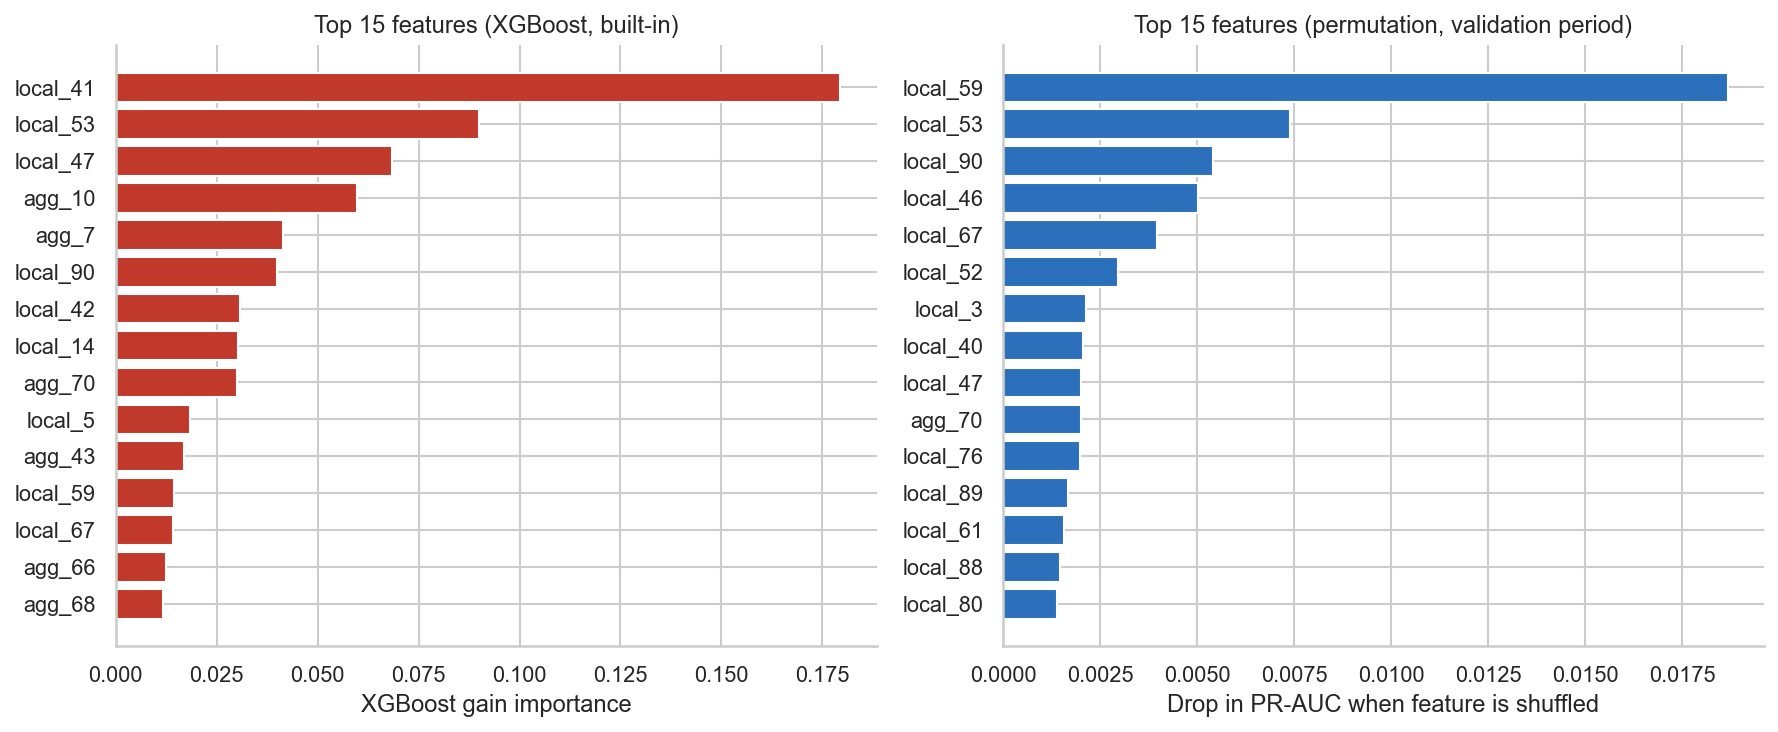

,rf_impurity,xgb_gain
feature,,
local_41,0.0401,0.1795
local_53,0.0415,0.0899
local_47,0.0520,0.0685
agg_10,0.0118,0.0597
agg_7,0.0103,0.0414
local_90,0.0266,0.0399
local_42,0.0041,0.0309
local_14,0.0185,0.0302


In [10]:
show("xai_01_importance", 1100)
imp = pd.read_csv(RES / "importance_tree.csv", index_col=0)
imp.sort_values("xgb_gain", ascending=False).head(8).round(4)

**Insight.** XGBoost relies heavily on a few local features (`local_41` alone carries 18% of the total gain; `local_53` 9%, `local_47` 7%), plus aggregated features `agg_10` and `agg_7`. Random Forest spreads importance more widely over the correlated block `local_41/43/47/49/53/55`. Permutation importance (drop in PR-AUC on validation data) ranks `local_59`, `local_53` and `local_90` highest, so different methods emphasise different members of correlated groups: individual rankings should not be over-interpreted, and the columns have no known real-world meaning.

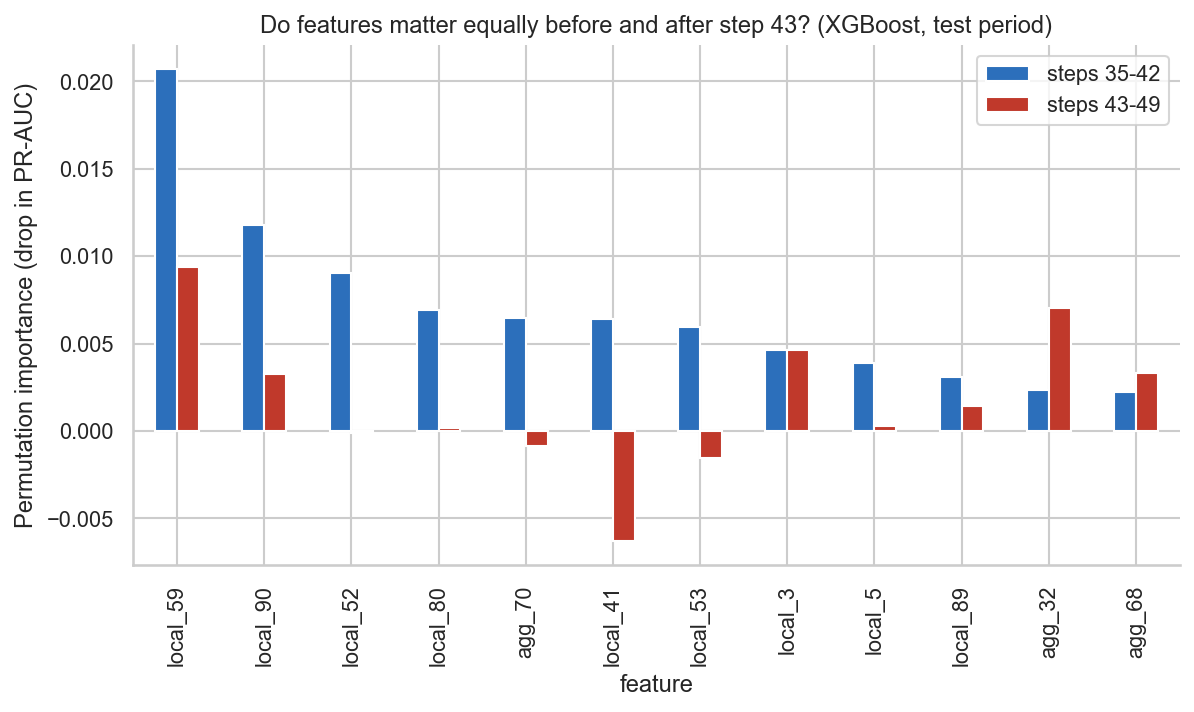

,steps_1-13,steps_14-27,steps_28-34
steps_1-13,1.00,0.40,0.32
steps_14-27,0.40,1.00,0.39
steps_28-34,0.32,0.39,1.00


In [11]:
show("xai_02_importance_over_time", 900)
pd.read_csv(RES / "importance_over_time_spearman.csv", index_col=0).round(2)

**Insight (do features stop mattering?).** Yes. Features that matter before step 43 lose power afterwards: permutation importance of `local_59` halves (0.021 → 0.009), `local_90` falls from 0.012 to 0.003, `local_52` and `agg_70` go to about zero, and `local_41` becomes *negative* (-0.006): shuffling it slightly *improves* PR-AUC, i.e. the model's use of it now misleads. In addition, the rank correlation of XGBoost's importance between models trained on different periods is only 0.32-0.40, so which features matter itself changes over time.

## Conclusions on the research questions
1. **Random vs temporal split**: a random split overstates F1 by 0.18-0.19 for the tree models (0.945/0.955 vs 0.757/0.776) and by 0.51 for Logistic Regression.
2. **Per-step collapse**: strong through step 42, collapse at step 43 (3 of 169 illicit transactions caught in steps 43-49). The cause appears to be a changed relationship between features and label rather than input shift alone; linking it to a darknet-market shutdown is a hypothesis.
3. **Tree vs graph model**: tree models are strong (test PR-AUC 0.78). Local features carry most of the signal; the supplied aggregated neighbour features add 0.01-0.03 PR-AUC. We did not train a GNN, so the tree-vs-GNN comparison remains open.
4. **Reducing drift damage**: retraining on recent labelled data helps substantially (F1 0.77 → 0.87 pooled; 0.03 → 0.54 in steps 43-49 for XGBoost) but needs fresh labels and does not restore early performance; dropping the 10% most-shifted features gives a small gain.
5. **Extension (Elliptic++ wallet addresses)**: not attempted (optional, time-permitting).